# 19 · ViT: 그림 조각이 서로 정보를 나누는 분류기

**이번 질문:** 그림을 작은 조각의 목록으로 바꾸면 Transformer가 어떻게 전체 숫자를 분류할까요? 조각의 내용과 위치는 어디에서 만나고, 손실 기울기는 화소까지 어떻게 돌아올까요?

작은 4×4 그림의 조각을 손으로 나눈 뒤, 고정 MNIST 숫자 7에서 같은 계산을 확인합니다. 패치 변환 → 임베딩·위치·CLS → 한 블록의 전체 미분 → 순열·계산 크기 → 실제 분류 학습 순서입니다.

- 준비물: [00](../00_기초/00_math_to_numpy.ipynb)·[00b](../00_기초/00b_vectorization.ipynb)의 축·reshape·벡터화, [01](../00_기초/01_gradients_and_learning.ipynb)의 중심차분, [02](../00_기초/02_probability_and_losses.ipynb)의 softmax·CE, [04](../00_기초/04_optimizers.ipynb)의 Adam, [08](../01_아키텍처/08_attention.ipynb)·[09](../01_아키텍처/09_transformer.ipynb)의 attention, [16](16_normalization.ipynb)의 LN, [17](17_resnet.ipynb)의 두 경로 미분입니다. 실험 해석은 [15](../02_연결/15_experiments_evaluation.ipynb)를 따릅니다.
- 도착점: 위치·CLS·세 LN의 γ·β를 포함해 **모든 학습 파라미터와 입력 화소를 검산**하고, 작은 MNIST ViT를 직접 학습합니다.
- 다음 연결: [20](20_sequence_encoder_decoder.ipynb)에서는 서로 다른 시퀀스를 잇는 attention을, [21](21_sets_graph_attention.ipynb)에서는 순서가 없는 집합·그래프의 대칭을 비교합니다. 다른 노트북을 import하거나 실행하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·축·구현 | 코드를 가리고 shape와 계산을 다시 씁니다 |
| 🔍 확인 | 그림·검산·실험 | 식의 주장과 실제 결과를 비교합니다 |
| 📎 참고 | 범위·코드 표기 | 필요한 자리에서 돌아옵니다 |
| ✏️ 연습 | 한두 줄 직접 채우기 | 손계산 후 검사하고 정답을 펼칩니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 패치로 나누는 재배열 자체는 가역입니다. 뒤의 선형 임베딩이나 pooling은 별도 연산이며 일반적으로 정보를 줄일 수 있습니다.
2. 내용 벡터에 위치 벡터를 더하고, 토큰 사이 attention·토큰 내부 MLP를 잔차 경로로 연결합니다. CLS와 평균 읽기는 같은 의미가 아닙니다.
3. 위치 없는 모델의 순열 대칭은 정확한 구조적 성질입니다. 위치를 넣거나 실제로 잘 학습되는지는 별도로 검산합니다.

| 기호 | shape | 의미 |
|---|---|---|
| $X$ | $(N,H,W)$ | 표본·세로·가로 순서의 회색 그림 |
| $B$ | $(N,T,P^2)$ | 패치 크기 $P$, 패치 수 $T=HW/P^2$인 화소 목록 |
| $Z,U,Y$ | $(N,L,d)$ | CLS를 포함한 토큰 $L=T+1$, 특징 폭 $d$ |
| $E$ | $(P^2,d)$ | 모든 패치에 공유하는 선형 임베딩 가중치 |
| $C,R$ | $(d,),(L,d)$ | 학습 가능한 CLS 벡터와 슬롯별 위치 벡터 |
| $Q,K,V,A$ | $(N,L,d),(N,L,d),(N,L,d),(N,L,L)$ | query·key·value와 attention 행 확률 |

[글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/vit_plots.py)

In [1]:
# 준비 셀: 프로젝트 경로·배열·자료·그림 도구를 불러옵니다.
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data.mnist import load_mnist, load_examples
from src.utils import setup_plots, run_check
from src.utils.vit_plots import (
    plot_patch_flow, plot_token_embedding, plot_attention_block, plot_permutation,
    plot_patch_budget, plot_classifier_flow, plot_vit_training, plot_vit_predictions,
    plot_cls_attention,
)
setup_plots()
print('NumPy', np.__version__, '· 작은 단일 블록 ViT를 NumPy로 만듭니다.')

NumPy 2.4.6 · 작은 단일 블록 ViT를 NumPy로 만듭니다.


📎 **실행과 원 모델과의 차이**

NumPy·Matplotlib·Jupyter를 사용하며, 첫 MNIST 호출은 자료가 없으면 내려받습니다.

> **용어** · **MNIST**는 28×28 화소의 숫자 0–9 손글씨 자료입니다. 한 **화소(pixel)**는 그림 한 칸의 잉크 양입니다.

개념 그림에는 `load_examples(download=True)`가 고르는 고정 10장을 씁니다. 작은 행렬에서는 커널을 시작하기 전 `OPENBLAS_NUM_THREADS=1`, `OMP_NUM_THREADS=1`로 스레드 비용을 줄일 수 있습니다.

[ViT 원문](https://arxiv.org/abs/2010.11929)은 패치 목록에 Transformer를 적용한 이미지 분류 모델을 제시합니다. 여기서는 큰 사전학습 모델의 재현 대신, **한 head·한 encoder 블록·폭 12·tanh MLP**로 계산을 줄입니다. dropout, Q/K/V의 편향, 다중 head, 사전학습, 위치 보간은 넣지 않습니다. 블록 앞 LN과 두 잔차 경로, 학습 가능한 위치·CLS, 최종 LN은 그대로 명시합니다. 작은 MNIST 결과로 원 논문 모델의 성능을 평가하지 않습니다.

> **코드** · `reshape`는 원소 순서를 유지하며 모양을 바꾸고, `transpose`는 축의 순서를 바꿉니다. `@`는 마지막 두 축의 행렬 곱이며 앞 배치 축은 유지합니다. `axis=-1`은 마지막 축입니다. `[:, None]`은 길이 1인 축을 추가합니다. `_`는 반환값 중 이번에 사용하지 않는 자리입니다.

## 🔑 1. 그림을 조각 목록으로 바꾸고 되돌립니다

**이 절에서 가져갈 것:** 패치의 위치 순서와 내부 화소 순서를 손계산·반복문·벡터화로 맞춥니다.

4×4 숫자판을 2×2 조각 네 개로 자른다고 합시다. 왼쪽 위 조각을 먼저 읽고, 오른쪽으로 이동한 뒤 다음 줄로 내려갑니다. 각 조각 안에서도 행부터 읽습니다. 이 규칙을 정하지 않으면 같은 숫자를 가지고도 다른 그림으로 돌아갈 수 있습니다.

> **용어** · **패치(patch)**는 그림의 작은 직사각형 조각입니다. **patchify**는 각 조각을 한 행으로 펴 목록을 만드는 재배열입니다. 겹치지 않고 빈틈없는 패치를 쓰면 원래 그림으로 되돌리는 **역변환(unpatchify)**이 있습니다.

$$X:(N,H,W)\to(N,H/P,P,W/P,P)\to(N,H/P,W/P,P,P)\to B:(N,T,P^2).$$

중간의 축 교환은 **패치 위치 두 축**을 먼저, **패치 안 두 축**을 뒤로 모읍니다. 여기서는 $H,W$가 $P$로 나누어지는 경우만 다루고 잘라내기·padding은 하지 않습니다.

$$\begin{bmatrix}0&1&2&3\\4&5&6&7\\8&9&10&11\\12&13&14&15\end{bmatrix}
\longleftrightarrow
\begin{bmatrix}0&1&4&5\\2&3&6&7\\8&9&12&13\\10&11&14&15\end{bmatrix}.$$

왼쪽은 그림이고 오른쪽의 각 행은 패치 하나입니다.

In [2]:
hand_image = np.arange(16).reshape(1,4,4)
hand_patches = np.array([[[0,1,4,5],[2,3,6,7],[8,9,12,13],[10,11,14,15]]])
hand_restored = hand_patches.reshape(1,2,2,2,2).transpose(0,1,3,2,4).reshape(1,4,4)

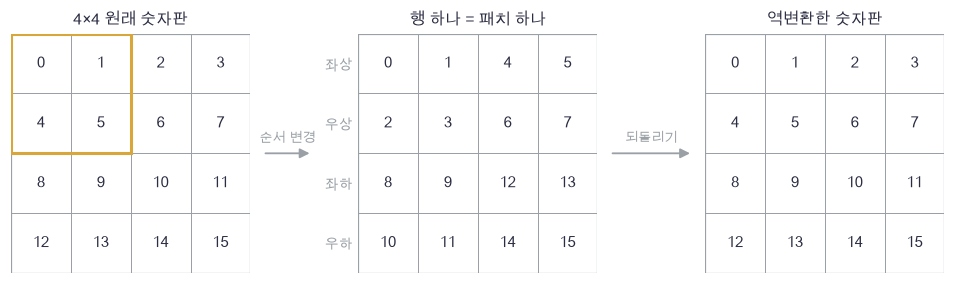

In [3]:
plot_patch_flow(hand_image[0], hand_patches[0], hand_restored[0], 2)

🔍 **그림 확인**

패치의 첫 행에는 그림의 왼쪽 위 네 숫자가 모여 있습니다. 역변환 뒤에는 0–15의 자리가 모두 돌아옵니다. 화소를 버린 압축이 아니라 배열의 순서를 바꾼 것입니다. 아래에서는 같은 규칙을 반복문으로 적고 축 교환 한 번으로 바꿉니다.

> **코드** · `a[start:stop]`은 시작을 포함하고 끝은 제외합니다. `reshape(...,-1)`의 `-1`은 전체 원소 수로 나머지 축의 길이를 계산합니다. `height//P`는 몫, `height % P`는 나머지입니다.

In [4]:
def patchify_loops(images, patch_size):
    """왼쪽 위부터 패치를 행으로 폅니다. images:(N,H,W) → (N,T,P²)."""
    n, height, width = images.shape
    assert height % patch_size == 0, "높이는 패치 크기로 나누어져야 합니다"
    assert width % patch_size == 0, "너비는 패치 크기로 나누어져야 합니다"
    rows, cols = height//patch_size, width//patch_size
    patches = np.empty((n, rows*cols, patch_size**2), dtype=images.dtype)
    for sample in range(n):
        for row in range(rows):
            for col in range(cols):
                patch = images[sample, row*patch_size:(row+1)*patch_size, col*patch_size:(col+1)*patch_size]
                patches[sample, row*cols+col] = patch.reshape(-1)
    return patches

In [5]:
def patchify(images, patch_size):
    """공간 축을 패치 위치·패치 내부로 분리합니다. (N,H,W) → (N,T,P²)."""
    n, height, width = images.shape
    assert patch_size > 0, "패치 크기는 양수여야 합니다"
    assert height % patch_size == 0, "높이는 패치 크기로 나누어져야 합니다"
    assert width % patch_size == 0, "너비는 패치 크기로 나누어져야 합니다"
    grouped = images.reshape(n, height//patch_size, patch_size, width//patch_size, patch_size)
    ordered = grouped.transpose(0,1,3,2,4)
    return ordered.reshape(n, -1, patch_size**2)

In [6]:
def unpatchify(patches, height, width, patch_size):
    """패치 순서와 내부 원소 순서를 되돌립니다. (N,T,P²) → (N,H,W)."""
    n, count, features = patches.shape
    assert count == (height//patch_size)*(width//patch_size), "패치 위치 수가 이미지 크기와 맞아야 합니다"
    assert features == patch_size**2, "한 패치의 화소 수가 맞아야 합니다"
    grouped = patches.reshape(n, height//patch_size, width//patch_size, patch_size, patch_size)
    return grouped.transpose(0,1,3,2,4).reshape(n, height, width)

In [7]:
# 쓰는 것: hand_image, hand_patches, hand_restored (1절 손계산)
loop_patches = patchify_loops(hand_image,2)
vector_patches = patchify(hand_image,2)
np.testing.assert_array_equal(loop_patches,hand_patches)  # 검산: 반복문 패치 네 행이 손계산과 같습니다.
np.testing.assert_array_equal(vector_patches,hand_patches)  # 검산: 축 교환 순서도 같은 행을 만듭니다.
np.testing.assert_array_equal(unpatchify(vector_patches,4,4,2),hand_image)  # 검산: 모든 원소가 원래 위치로 돌아옵니다.
rectangular = np.arange(48).reshape(2,4,6)
np.testing.assert_array_equal(unpatchify(patchify(rectangular,2),4,6,2),rectangular)  # 검산: 표본 두 개·직사각형에서도 정확히 역변환합니다.
print('패치 손계산·반복문·벡터화·역변환 통과')

패치 손계산·반복문·벡터화·역변환 통과


### ✏️ 연습 1 · 패치 수와 화소 수 세기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

그림 높이·너비가 패치 크기로 나누어집니다. 패치 수 `tokens`와 한 패치의 화소 수 `features`를 두 줄로 채우세요.

In [8]:
def exercise_patch_shape(height,width,patch_size):
    """공간 위치 수와 패치 내부 원소 수를 구별합니다."""
    raise NotImplementedError
    return tokens,features

In [9]:
def check_patch_shape(candidate):
    """28×28 그림을 7×7로 나누면 16개 조각·49개 화소입니다."""
    assert candidate(28,28,7)==(16,49), "위치 4×4=16, 내부 7×7=49여야 합니다"
run_check(check_patch_shape,exercise_patch_shape)

☐ exercise_patch_shape: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
tokens = (height//patch_size)*(width//patch_size)
features = patch_size**2
```

</details>

## 🔑 2. 내용 벡터에 위치와 CLS를 붙입니다

**이 절에서 가져갈 것:** 공유 패치 임베딩·슬롯별 위치·CLS와 두 가지 읽기 규칙을 구분합니다.

숫자 7의 위쪽 가로획과 아래쪽 빈 공간은 모양도 자리도 다릅니다. 각 패치를 같은 선형 변환으로 특징 벡터에 옮긴 다음, 어느 자리에 있었는지 별도의 학습 가능한 벡터를 더합니다.

$$E_{patch}=BE+b_e,\qquad Z=[C;E_{patch}]+R.$$

$E$는 $(P^2,d)$, $b_e,C$는 $(d,)$, $R$은 $(T+1,d)$입니다. 앞에 $C$ 한 행을 붙여 토큰 수가 $L=T+1$이 됩니다. 모든 이미지가 같은 초기 CLS 파라미터를 공유하지만, attention을 통과한 CLS 출력은 각 이미지 내용에 따라 달라질 수 있습니다.

> **용어** · **토큰(token)**은 Transformer가 처리하는 벡터 한 행입니다. **임베딩(embedding)**은 패치 화소를 특징 벡터로 옮기는 학습 가능한 변환입니다. **위치 임베딩**은 고정 슬롯마다 갖는 벡터이며 여기에선 내용 벡터와 더합니다. **CLS 토큰**은 분류에 쓸 정보를 모으도록 학습하는 특별한 행입니다.

encoder의 최종 출력이 $Y:(N,L,d)$일 때 두 읽기 규칙은

$$r_{CLS}=Y[:,0,:],\qquad r_{mean}=\frac1T\sum_{t=1}^T Y[:,t,:].$$

mean은 **같은 CLS 포함 encoder**의 패치 출력만 평균합니다. CLS를 애초에 없앤 별도 GAP 구조와 동일하다고 주장하지 않습니다. encoder를 지나기 전 CLS는 이미지와 무관한 공유 벡터이므로 그것만 바로 읽으면 이미지 정보를 얻을 수 없습니다.

> **용어** · **pooling(모아 읽기)**은 여러 토큰의 정보를 한 벡터로 줄이는 규칙입니다. **GAP(global average pooling)**는 전체 위치의 특징을 평균하는 읽기 방법을 가리킵니다.

In [10]:
# 쓰는 것: patchify (1절)
mnist_examples,mnist_example_labels = load_examples(download=True)
example_seven = mnist_examples[7]
example_patches = patchify(example_seven[None,:,:],7)
embedding_rng = np.random.default_rng(1900)
embedding_params = {
    'We':embedding_rng.normal(size=(49,6))/7, 'be':np.zeros(6),
    'cls':np.array([.1,-.1,.2,0.,.1,-.2]), 'pos':embedding_rng.normal(0,.08,size=(17,6)),
}
example_embedded = example_patches @ embedding_params['We']+embedding_params['be']
example_base = np.concatenate([embedding_params['cls'][None,None,:],example_embedded],axis=1)
example_tokens = example_base+embedding_params['pos'][None,:,:]

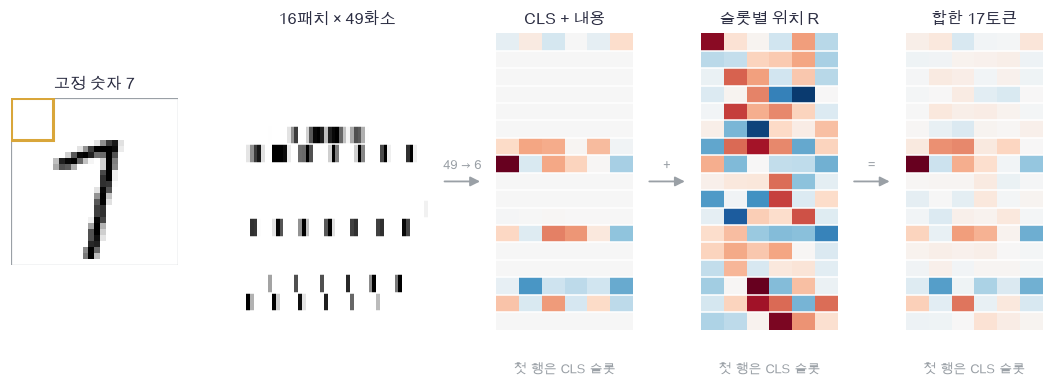

In [11]:
plot_token_embedding(example_seven, example_patches[0], example_base[0], embedding_params["pos"], example_tokens[0], 7)

🔍 **그림 확인**

화소 패치 행은 길이 49, 임베딩 행은 길이 6입니다. 첫 행은 이미지 조각이 아닌 CLS이고 위치 표에도 CLS 슬롯이 있습니다. 위치가 없는 경우 모든 패치에 같은 변환을 적용하므로, 목록의 행 번호 자체는 모델이 읽는 숫자가 아닙니다.

> **코드** · `np.concatenate(...,axis=1)`은 기존 토큰 축에 행을 이어 붙입니다. `np.broadcast_to`는 같은 CLS를 표본 수만큼 읽을 수 있는 모양으로 펼칩니다. `params['pos'][None,:,:]`의 새 표본 축 때문에 모든 이미지에 같은 위치 표가 더해집니다.

In [12]:
def embed_tokens(patches, params, use_position=True):
    """패치 선형 임베딩 앞에 공유 CLS를 붙이고 슬롯별 위치 벡터를 더합니다."""
    embedded = patches @ params['We'] + params['be']
    cls_batch = np.broadcast_to(params['cls'], (len(patches),1,len(params['cls'])))
    tokens = np.concatenate([cls_batch, embedded], axis=1)
    if use_position:
        tokens = tokens + params['pos'][None, :, :]
    return tokens

In [13]:
def pool_tokens(tokens, mode):
    """같은 encoder의 CLS 행 또는 CLS를 제외한 패치 행 평균을 읽습니다."""
    if mode == 'cls':
        return tokens[:,0,:]
    if mode == 'mean':
        return tokens[:,1:,:].mean(axis=1)
    raise ValueError("mode는 cls 또는 mean이어야 합니다")

In [14]:
# 쓰는 것: example_patches, example_tokens, embedding_params (2절 그림)
actual_tokens = embed_tokens(example_patches,embedding_params)
np.testing.assert_allclose(actual_tokens,example_tokens)  # 검산: 임베딩 함수는 그림의 직접 계산과 같습니다.
readout_probe = np.array([[[9.,-1.],[1.,2.],[3.,6.]]])
np.testing.assert_array_equal(pool_tokens(readout_probe,'cls'),[[9.,-1.]])  # 검산: CLS는 첫 행입니다.
np.testing.assert_allclose(pool_tokens(readout_probe,'mean'),[[2.,4.]])  # 검산: CLS를 제외한 두 행만 평균합니다.
print('공유 임베딩·위치 덧셈·CLS/패치 평균 읽기 확인')

공유 임베딩·위치 덧셈·CLS/패치 평균 읽기 확인


### ✏️ 연습 2 · CLS를 제외한 평균 읽기

`encoded:(N,T+1,d)`의 첫 행은 CLS입니다. 나머지 패치 토큰의 평균 벡터 한 줄을 채우세요.

In [15]:
def exercise_patch_mean(encoded):
    """CLS를 빼고 패치 위치 축만 평균합니다."""
    raise NotImplementedError
    return pooled

In [16]:
def check_patch_mean(candidate):
    """첫 행의 큰 값이 평균에 들어가지 않도록 검사합니다."""
    encoded=np.array([[[100.,100.],[2.,0.],[4.,6.]]])
    np.testing.assert_allclose(candidate(encoded),[[3.,3.]])  # 검산: 패치 두 행의 평균은 [3,3]입니다.
run_check(check_patch_mean,exercise_patch_mean)

☐ exercise_patch_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
pooled = encoded[:,1:,:].mean(axis=1)
```

</details>

## 🔑 3. attention·LN·MLP를 연결하고 모두 미분합니다

**이 절에서 가져갈 것:** 한 encoder 블록의 forward와 backward를 쓰고, 위치·CLS·LN까지 빠짐없이 수치 검산합니다.

위쪽 패치의 가로획이 아래쪽 패치의 특징을 읽을 수 있게 합쳐 보겠습니다. 먼저 토큰마다 특징 축을 정규화하고, 모든 토큰 쌍의 닮음으로 정보를 섞습니다. 그다음 각 토큰의 특징을 같은 MLP로 다시 바꿉니다.

$$U=\mathrm{LN}_1(Z),\quad Q=UW_Q,\quad K=UW_K,\quad V=UW_V,$$
$$S=QK^T/\sqrt d,\quad A=\mathrm{softmax}_{\text{key축}}(S),\quad H=Z+(AV)W_O+b_O,$$
$$U_2=\mathrm{LN}_2(H),\quad M=\tanh(U_2W_{m1}+b_{m1}),\quad Y=H+MW_{m2}+b_{m2},$$
$$Y_f=\mathrm{LN}_f(Y),\quad \mathrm{logits}=\mathrm{pool}(Y_f)W_h+b_h.$$

$S,A$는 $(N,L,L)$이고 **행은 읽는 query, 열은 읽히는 key**입니다. 마지막 축으로 softmax하므로 각 행의 합은 1입니다. 각 $W_Q,W_K,W_V,W_O$는 $(d,d)$, $W_{m1},W_{m2}$는 $(d,m),(m,d)$입니다. LN은 $(N,L,d)$의 **마지막 d축만** 정규화하고 γ·β는 토큰·표본 사이에 공유합니다.

> **용어** · **self-attention**은 같은 토큰 목록에서 query·key·value를 만들어 정보를 모으는 연산입니다. **query**는 무엇을 읽을지, **key**는 읽힐 기준, **value**는 전달할 내용 벡터입니다. **head**는 이런 가중합 한 묶음이며 여기서는 하나입니다. **pre-LN**은 각 수정 연산 앞에 LN을 두는 위치입니다. **MLP**는 각 토큰에 공유하는 두 선형 층과 비선형 함수입니다.

In [17]:
# 그림용 작은 3토큰·3특징: LN과 attention을 직접 배열 연산으로 잇습니다.
block_tokens = np.array([[[.1,.3,-.2],[.4,-.1,.2],[-.2,.5,.1]]])
block_centered = block_tokens-block_tokens.mean(axis=-1,keepdims=True)
block_norm = block_centered/np.sqrt(np.mean(block_centered**2,axis=-1,keepdims=True)+1e-5)
block_params = {'Wq':np.eye(3), 'Wk':np.diag([.5,1.,.8]), 'Wv':np.eye(3), 'Wo':np.eye(3)*.2,'bo':np.zeros(3)}
block_q = block_norm @ block_params['Wq']
block_k = block_norm @ block_params['Wk']
block_v = block_norm @ block_params['Wv']
block_scores = (block_q @ block_k.swapaxes(-1,-2))/np.sqrt(3)
block_exp = np.exp(block_scores-block_scores.max(axis=-1,keepdims=True))
block_attention = block_exp/block_exp.sum(axis=-1,keepdims=True)
block_branch = (block_attention @ block_v) @ block_params['Wo']
block_sum = block_tokens+block_branch

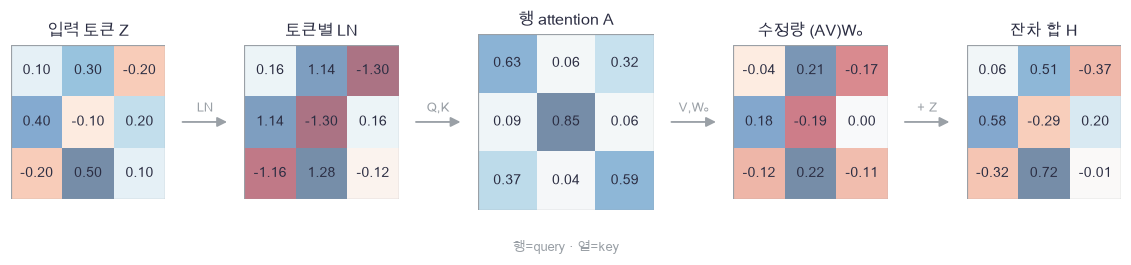

In [18]:
plot_attention_block(block_tokens[0], block_norm[0], block_attention[0], block_branch[0], block_sum[0])

🔍 **그림 확인과 미분 경로**

각 attention 행은 여러 value 행을 얼마나 읽는지 나타냅니다. 수정량을 만들고 원래 토큰에 더한 뒤에도 토큰 수·특징 폭은 같습니다. 마지막 두 판은 잔차의 합이고 다음 MLP도 같은 방식으로 연결합니다.

행렬 미분의 핵심은 attention 행 확률을 미분하는 것입니다. $C=AV$, 상류 기울기를 $G_C$라 두면

$$dA=G_CV^T,\quad dV=A^TG_C,\qquad dS=A\odot[dA-\operatorname{sum}_{last}(dA\odot A)],$$
$$dQ=dSK/\sqrt d,\quad dK=dS^TQ/\sqrt d,\qquad
 dU=dQW_Q^T+dKW_K^T+dVW_V^T.$$

$S$의 전치는 각 표본 안 마지막 두 축을 바꿉니다. 모든 토큰·표본에서 공유하는 가중치는 해당 두 축의 기여를 합합니다. 예를 들어 $dW_Q=U_{flat}^T(dQ)_{flat}$이며 $U_{flat}:(NL,d)$입니다.

LN은 $\hat U=(U-\mu)r$, $r=(v+\epsilon)^{-1/2}$, $g=dY\odot\gamma$에서

$$dU=r[g-\operatorname{mean}_{last}(g)-\hat U\operatorname{mean}_{last}(g\odot\hat U)].$$

γ를 먼저 곱한 뒤 특징 축으로 평균해야 합니다. $d\gamma=\sum_{N,L}dY\odot\hat U$, $d\beta=\sum_{N,L}dY$입니다. 두 잔차에서는 직접 경로의 기울기와 수정 경로의 기울기를 더합니다. 마지막 임베딩은 $dE=B_{flat}^T(dZ_{patch})_{flat}$이며 위치·CLS는 공유된 표본 축으로 합합니다.

> **코드** · `swapaxes(-1,-2)`는 배치 축을 유지한 전치입니다. `keepdims=True`는 합친 축을 길이 1로 남겨 원래 행에 다시 적용합니다. cache 사전은 중간 배열을 이름으로 저장해 backward가 다시 쓰게 합니다. `gradients.update(other)`는 다른 경로의 이름별 기울기를 합친 사전에 추가합니다.

In [19]:
def layer_norm_forward(x, gamma, beta, epsilon=1e-5):
    """각 토큰의 d축만 정규화합니다. x:(N,L,d), gamma,beta:(d,) → y,cache."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1/np.sqrt(np.mean(centered**2, axis=-1, keepdims=True)+epsilon)
    normalized = centered*inverse
    return normalized*gamma+beta, (normalized,inverse,gamma)

In [20]:
def layer_norm_backward(dy, cache):
    """토큰별 평균·분산 경로를 포함하고 gamma,beta는 N,L축으로 합합니다."""
    normalized,inverse,gamma = cache
    g = dy*gamma
    dx = inverse*(g-g.mean(axis=-1,keepdims=True)-normalized*np.mean(g*normalized,axis=-1,keepdims=True))
    dgamma = np.sum(dy*normalized,axis=(0,1))
    dbeta = np.sum(dy,axis=(0,1))
    return dx,dgamma,dbeta

In [21]:
def attention_forward(x, params):
    """단일 head self-attention. x:(N,L,d) → output:(N,L,d), cache."""
    q = x @ params['Wq']
    k = x @ params['Wk']
    v = x @ params['Wv']
    scores = (q @ k.swapaxes(-1,-2))/np.sqrt(x.shape[-1])
    shifted = scores-scores.max(axis=-1,keepdims=True)
    exponent = np.exp(shifted)
    attention = exponent/exponent.sum(axis=-1,keepdims=True)
    context = attention @ v
    output = context @ params['Wo'] + params['bo']
    return output,(x,q,k,v,attention,context)

In [22]:
def attention_backward(dy, cache, params):
    """softmax 행·Q·K·V 경로를 모두 미분하고 같은 입력의 기여를 더합니다."""
    # 1. 출력 투영을 거슬러 context와 attention 확률로 갑니다.
    x,q,k,v,attention,context = cache
    width = x.shape[-1]
    flat_x = x.reshape(-1,width)
    dcontext = dy @ params['Wo'].T
    gradients = {'Wo': context.reshape(-1,width).T @ dy.reshape(-1,width), 'bo':dy.sum(axis=(0,1))}
    da = dcontext @ v.swapaxes(-1,-2)
    dv = attention.swapaxes(-1,-2) @ dcontext
    # 2. 행 softmax의 야코비안을 곱한 뒤 Q·K를 미분합니다.
    ds = attention*(da-np.sum(da*attention,axis=-1,keepdims=True))
    dq = (ds @ k)/np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q)/np.sqrt(width)
    gradients['Wq'] = flat_x.T @ dq.reshape(-1,width)
    gradients['Wk'] = flat_x.T @ dk.reshape(-1,width)
    gradients['Wv'] = flat_x.T @ dv.reshape(-1,width)
    dx = dq @ params['Wq'].T + dk @ params['Wk'].T + dv @ params['Wv'].T
    return dx,gradients

In [23]:
# 쓰는 것: block_tokens,block_norm,block_params,block_attention,block_branch (3절 직접 계산), layer_norm_forward (3절)
actual_norm,_ = layer_norm_forward(block_tokens,np.ones(3),np.zeros(3))
actual_branch,attention_cache = attention_forward(actual_norm,block_params)
np.testing.assert_allclose(actual_norm,block_norm)  # 검산: 토큰별 LN은 그림의 직접 계산과 같습니다.
np.testing.assert_allclose(actual_branch,block_branch)  # 검산: 실제 attention의 수정량도 같습니다.
np.testing.assert_allclose(attention_cache[4],block_attention)  # 검산: cache의 행 확률은 직접 softmax와 같습니다.
np.testing.assert_allclose(block_attention.sum(axis=-1),1.)  # 검산: key 축을 합하면 모든 query 행이 1입니다.
print('LN·attention·잔차 그림 계산과 구현 일치')

LN·attention·잔차 그림 계산과 구현 일치


📎 **전체 모델을 검산할 스칼라 손실**

이제 그림 조각부터 최종 분류 점수까지 한 함수로 잇습니다. 표본 평균 CE를 사용합니다.

$$L=-\frac1N\sum_n\log p_{n,t_n},\qquad p=\mathrm{softmax}(\mathrm{logits}),\quad
 d\mathrm{logits}=(p-\mathrm{onehot}(t))/N.$$

> **용어** · **logit**은 확률로 바꾸기 전 클래스 점수이고, **교차 엔트로피(CE)**는 정답 클래스의 음의 로그 확률입니다.

그 미분을 모든 경로로 돌린 뒤 4×4 그림·2×2 패치·폭 3·MLP 폭 4·클래스 3인 작은 모델에서 모든 원소를 중심차분합니다. 학습 가능한 배열은 21개이며, 위치·CLS·세 LN의 γ·β도 검사 대상입니다. CLS와 평균 읽기를 각각 검사합니다.

> **코드** · `params.items()`는 파라미터 이름과 배열을 함께 꺼냅니다. `rng.normal(size=...)`은 지정한 모양의 정규 난수를 만듭니다. `np.ndindex(shape)`는 배열의 모든 인덱스를 방문합니다. `try/finally`는 수치미분 중 오류가 나도 원본 값을 복구합니다. `logp[rows,labels]`는 각 행에서 그 표본의 정답 열을 고릅니다.

> **코드** · `{key:values[key] for key in names}`는 필요한 이름만 모은 사전을 만듭니다. 여기서는 일부 파라미터의 검산 오차를 짧게 출력하는 데만 씁니다.

In [24]:
def init_vit(patch_features, token_count, width=12, hidden=24, classes=10, seed=190):
    """임베딩·CLS·위치·단일 encoder·분류기의 학습 파라미터를 초기화합니다."""
    rng = np.random.default_rng(seed)
    params = {'We':rng.normal(size=(patch_features,width))/np.sqrt(patch_features),
              'be':np.zeros(width), 'cls':rng.normal(0,.02,size=width),
              'pos':rng.normal(0,.02,size=(token_count+1,width))}
    for name in ['Wq','Wk','Wv','Wo']:
        params[name] = rng.normal(size=(width,width))/np.sqrt(width)
    params['bo'] = np.zeros(width)
    params['Wm1'] = rng.normal(size=(width,hidden))/np.sqrt(width)
    params['bm1'] = np.zeros(hidden)
    params['Wm2'] = rng.normal(size=(hidden,width))/np.sqrt(hidden)
    params['bm2'] = np.zeros(width)
    for suffix in ['1','2','f']:
        params['gamma'+suffix] = np.ones(width)
        params['beta'+suffix] = np.zeros(width)
    params['Wh'] = rng.normal(size=(width,classes))/np.sqrt(width)
    params['bh'] = np.zeros(classes)
    return params

In [25]:
# 쓰는 것: embed_tokens,pool_tokens (2절), layer_norm_forward,attention_forward (3절)
def vit_forward(patches, params, pooling='cls', use_position=True):
    """임베딩→pre-LN attention→pre-LN MLP→최종 LN→readout을 계산합니다."""
    # 1. 위치와 CLS를 넣고 attention 수정량을 더합니다.
    tokens = embed_tokens(patches, params, use_position)
    n1,ln1_cache = layer_norm_forward(tokens,params['gamma1'],params['beta1'])
    attended,attention_cache = attention_forward(n1,params)
    h = tokens+attended
    # 2. 각 토큰에 같은 MLP를 적용하고 두 번째 잔차 합을 만듭니다.
    n2,ln2_cache = layer_norm_forward(h,params['gamma2'],params['beta2'])
    hidden = np.tanh(n2 @ params['Wm1']+params['bm1'])
    y = h+hidden @ params['Wm2']+params['bm2']
    normalized,final_cache = layer_norm_forward(y,params['gammaf'],params['betaf'])
    pooled = pool_tokens(normalized,pooling)
    logits = pooled @ params['Wh']+params['bh']
    cache = {'patches':patches,'ln1':ln1_cache,'attention':attention_cache,'n2':n2,
             'ln2':ln2_cache,'hidden':hidden,'final_ln':final_cache,'encoded':normalized,
             'pooled':pooled,'pooling':pooling,'use_position':use_position}
    return logits,cache

In [26]:
# 쓰는 것: layer_norm_backward,attention_backward (3절)
def vit_backward(dlogits, cache, params):
    """모든 학습 파라미터와 패치 화소의 미분을 구합니다. dpatches:(N,T,P²)."""
    # 1. 분류기와 읽기 연산의 미분을 원래 토큰 자리로 돌려줍니다.
    patches,n2,hidden = cache['patches'],cache['n2'],cache['hidden']
    normalized,pooled,pooling = cache['encoded'],cache['pooled'],cache['pooling']
    gradients = {'Wh':pooled.T @ dlogits,'bh':dlogits.sum(axis=0)}
    dpooled = dlogits @ params['Wh'].T
    dnormalized = np.zeros_like(normalized)
    if pooling == 'cls':
        dnormalized[:,0,:] = dpooled
    else:
        dnormalized[:,1:,:] = dpooled[:,None,:]/patches.shape[1]
    dy,gradients['gammaf'],gradients['betaf'] = layer_norm_backward(dnormalized,cache['final_ln'])
    # 2. MLP 잔차의 직접 경로와 수정 경로를 합합니다.
    width = normalized.shape[-1]
    dhidden = dy @ params['Wm2'].T
    du = dhidden*(1-hidden**2)
    gradients['Wm2'] = hidden.reshape(-1,hidden.shape[-1]).T @ dy.reshape(-1,width)
    gradients['bm2'] = dy.sum(axis=(0,1))
    gradients['Wm1'] = n2.reshape(-1,width).T @ du.reshape(-1,hidden.shape[-1])
    gradients['bm1'] = du.sum(axis=(0,1))
    dn2 = du @ params['Wm1'].T
    dh_norm,gradients['gamma2'],gradients['beta2'] = layer_norm_backward(dn2,cache['ln2'])
    dh = dy+dh_norm
    # 3. attention 잔차와 첫 LN을 거쳐 입력 토큰으로 돌아갑니다.
    dn1,attention_gradients = attention_backward(dh,cache['attention'],params)
    gradients.update(attention_gradients)
    dz_norm,gradients['gamma1'],gradients['beta1'] = layer_norm_backward(dn1,cache['ln1'])
    dz = dh+dz_norm
    # 4. 공유 위치·CLS는 표본 축으로 합하고 패치 선형층을 미분합니다.
    gradients['pos'] = dz.sum(axis=0) if cache['use_position'] else np.zeros_like(params['pos'])
    gradients['cls'] = dz[:,0,:].sum(axis=0)
    dembedded = dz[:,1:,:]
    gradients['We'] = patches.reshape(-1,patches.shape[-1]).T @ dembedded.reshape(-1,width)
    gradients['be'] = dembedded.sum(axis=(0,1))
    dpatches = dembedded @ params['We'].T
    return dpatches,gradients

In [27]:
def cross_entropy(logits, labels):
    """안정적인 log-softmax와 표본 평균 CE. logits:(N,K), labels:(N,) → loss,dlogits."""
    shifted = logits-logits.max(axis=1,keepdims=True)
    logp = shifted-np.log(np.exp(shifted).sum(axis=1,keepdims=True))
    rows = np.arange(len(labels))
    loss = -logp[rows,labels].mean()
    gradient = np.exp(logp)
    gradient[rows,labels] -= 1
    gradient /= len(labels)
    return float(loss),gradient

In [28]:
def central_difference(objective, array, step=1e-6):
    """고정 스칼라 함수를 모든 원소에서 중심차분하고 원본 배열을 복구합니다."""
    gradient = np.empty_like(array)
    for index in np.ndindex(array.shape):
        original = array[index]
        try:
            array[index] = original+step
            plus = objective()
            array[index] = original-step
            minus = objective()
        finally:
            array[index] = original
        gradient[index] = (plus-minus)/(2*step)
    return gradient

In [29]:
# 쓰는 것: patchify,unpatchify (1절), init_vit,vit_forward,vit_backward,cross_entropy,central_difference (3절)
def check_full_vit(pooling):
    """4×4 이미지·패치2·d3에서 21개 파라미터 배열과 입력 전체를 검사합니다."""
    rng = np.random.default_rng(191)
    images = rng.normal(.2,.3,size=(2,4,4))
    labels = np.array([0,2])
    params = init_vit(4,4,width=3,hidden=4,classes=3,seed=192)
    logits,cache = vit_forward(patchify(images,2),params,pooling)
    _,dlogits = cross_entropy(logits,labels)
    dpatches,gradients = vit_backward(dlogits,cache,params)
    dx = unpatchify(dpatches,4,4,2)
    def objective():
        """현재 이미지와 파라미터에서 같은 CE를 다시 계산합니다."""
        scores,_ = vit_forward(patchify(images,2),params,pooling)
        loss,_ = cross_entropy(scores,labels)
        return loss
    errors = {}
    for name,value in params.items():
        numeric = central_difference(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,rtol=8e-5,atol=3e-8)  # 검산: 해당 파라미터의 모든 원소 미분이 같습니다.
        errors[name] = float(np.max(np.abs(gradients[name]-numeric)))
    numeric_x = central_difference(objective,images)
    np.testing.assert_allclose(dx,numeric_x,rtol=8e-5,atol=3e-8)  # 검산: 패치 역변환까지 포함한 모든 입력 화소의 미분이 같습니다.
    errors['input'] = float(np.max(np.abs(dx-numeric_x)))
    return errors

In [30]:
cls_errors = check_full_vit('cls')
mean_errors = check_full_vit('mean')
print('CLS · 21개 파라미터 배열+입력 최대 절대오차:',max(cls_errors.values()))
print('mean · 21개 파라미터 배열+입력 최대 절대오차:',max(mean_errors.values()))
print('위치/CLS/LN 최대오차:',{key:cls_errors[key] for key in ['pos','cls','gamma1','beta1','gamma2','beta2','gammaf','betaf']})

CLS · 21개 파라미터 배열+입력 최대 절대오차: 1.8596133521953107e-09
mean · 21개 파라미터 배열+입력 최대 절대오차: 1.920780201558614e-10
위치/CLS/LN 최대오차: {'pos': 1.8596133521953107e-09, 'cls': 1.748591049732795e-09, 'gamma1': 1.337025490322219e-10, 'beta1': 1.2804617782746774e-10, 'gamma2': 9.781028764699329e-11, 'beta2': 5.1795942535015627e-11, 'gammaf': 4.646821816223223e-11, 'betaf': 1.1855283421624563e-10}


### ✏️ 연습 3 · softmax 한 행의 역전파

`attention`과 그 확률에 대한 상류 기울기 `da`는 `(N,L,L)`입니다. 점수 기울기 `ds` 한 줄을 채우세요.

In [31]:
def exercise_attention_gradient(attention,da):
    """각 query 행의 softmax 미분을 key 축으로 계산합니다."""
    raise NotImplementedError
    return ds

In [32]:
def check_attention_gradient(candidate):
    """확률 .25·.75에서 상류 2·-2를 받은 한 행을 검사합니다."""
    actual=candidate(np.array([[[.25,.75]]]),np.array([[[2.,-2.]]]))
    np.testing.assert_allclose(actual,[[[.75,-.75]]])  # 검산: 확률 가중평균 -1을 뺀 뒤 각각 곱합니다.
run_check(check_attention_gradient,exercise_attention_gradient)

☐ exercise_attention_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ds = attention*(da-np.sum(da*attention,axis=-1,keepdims=True))
```

</details>

## 🔑 4. 위치를 바꾸는 순열과 패치 크기를 구별합니다

**이 절에서 가져갈 것:** 위치 없는 모델의 순열 대칭을 검산하고, 패치 크기가 토큰·파라미터·attention 배열에 미치는 영향을 계산합니다.

같은 그림 조각을 봉투에 담아 순서를 섞었다고 합시다. 위치 정보가 없다면 모델은 조각 목록의 순서만으로 원래 자리를 알 수 없습니다. 위치 표를 고정한 채 내용만 섞으면 각 조각에 붙은 위치 벡터가 달라집니다.

패치 행 순열 $\Pi$에 CLS 첫 행을 고정한 순열 $\widetilde\Pi=\operatorname{diag}(1,\Pi)$를 생각합니다. 위치가 없으면 LN·공유 MLP는 토큰 순열에 따라 그대로 움직이고,

$$Q'=\widetilde\Pi Q,\quad K'=\widetilde\Pi K,\quad A'=\widetilde\Pi A\widetilde\Pi^T,\quad Y'_f=\widetilde\Pi Y_f.$$

따라서 CLS 읽기와 패치 평균 읽기의 최종 점수는 둘 다 같습니다. **토큰 출력의 순열 등변성**에서 **읽은 점수의 순열 불변성**이 따라옵니다. 원래 화소 그림의 모든 순열에 대해 같다는 뜻은 아닙니다. 패치 내부 화소를 섞으면 선형 임베딩 입력 자체가 달라집니다.

위치가 있을 때는 두 경우를 나눕니다. 내용만 섞고 위치 슬롯을 고정하면 보통 결과가 달라집니다. 내용과 그에 붙은 위치 벡터를 **함께 같은 순서로 옮기면** 토큰의 재정렬일 뿐이므로 읽기 결과가 다시 같습니다.

> **용어** · **순열(permutation)**은 항목의 순서만 바꾸는 것입니다. **등변(equivariant)**은 입력 순서를 바꾸면 출력 순서도 같은 방식으로 바뀐다는 뜻입니다. **불변(invariant)**은 그 변환 뒤 최종 출력이 같다는 뜻입니다.

In [33]:
# 쓰는 것: unpatchify (1절), init_vit,vit_forward (3절)
symmetry_patches=np.array([[[.1,.2,.3,.4],[.4,.5,.6,.7],[.8,.9,1.,.3],[.2,.3,.7,.9]]])
patch_order=np.array([2,0,3,1])
token_order=np.concatenate([np.array([0]),patch_order+1])
symmetry_params=init_vit(4,4,width=3,hidden=4,classes=3,seed=192)
symmetry_original=unpatchify(symmetry_patches,4,4,2)[0]
symmetry_shuffled=unpatchify(symmetry_patches[:,patch_order],4,4,2)[0]
no_position_original,_=vit_forward(symmetry_patches,symmetry_params,use_position=False)
no_position_shuffled,_=vit_forward(symmetry_patches[:,patch_order],symmetry_params,use_position=False)
position_original,_=vit_forward(symmetry_patches,symmetry_params)
position_shuffled,_=vit_forward(symmetry_patches[:,patch_order],symmetry_params)
no_position_scores=np.concatenate([no_position_original,no_position_shuffled],axis=0)
position_scores=np.concatenate([position_original,position_shuffled],axis=0)

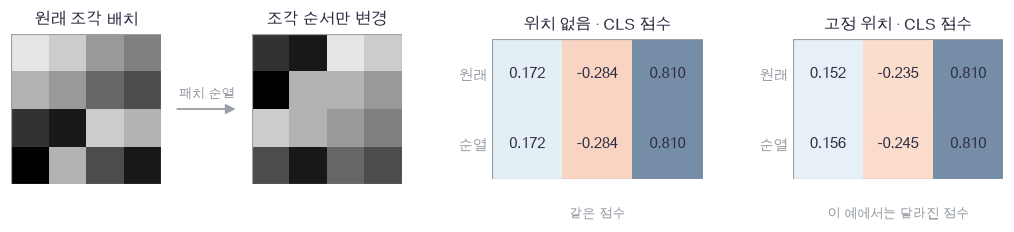

In [34]:
plot_permutation(symmetry_original, symmetry_shuffled, no_position_scores, position_scores)

🔍 **그림 확인**

그림 조각의 자리는 달라졌지만 위치 없는 CLS 점수는 같습니다. 위치를 고정한 모델은 이 예제에서 다른 점수를 냅니다. **모든 파라미터에서 반드시 달라진다는 보장**은 아닙니다. 위치 벡터가 모두 같거나 모델이 위치를 무시하면 같을 수도 있습니다.

아래에서는 최종 점수뿐 아니라 모든 encoded 토큰 행의 순서까지 대조합니다. 위치를 함께 옮기는 검사는 위치 파라미터 사본을 만들어 원래 모델은 바꾸지 않습니다.

> **코드** · `array[:,order]`는 모든 표본의 토큰 축을 같은 순서로 고릅니다. `{name:value.copy() for ...}`는 모든 파라미터를 독립 복사합니다. `np.concatenate([ [0], order+1 ])`는 CLS를 0에 고정하고 패치 행 번호만 한 칸 뒤로 옮깁니다.

위치 없는 계산은 여기서 초기화 모델의 대칭을 검사하는 용도입니다. 별도로 학습한 no-position 모델의 성능을 측정한 실험은 아닙니다.

In [35]:
# 쓰는 것: symmetry_patches,symmetry_params,patch_order,token_order (4절), vit_forward (3절)
moved_position={name:value.copy() for name,value in symmetry_params.items()}
moved_position['pos']=symmetry_params['pos'][token_order].copy()
for pooling in ['cls','mean']:
    base,base_cache=vit_forward(symmetry_patches,symmetry_params,pooling,False)
    shuffled,shuffled_cache=vit_forward(symmetry_patches[:,patch_order],symmetry_params,pooling,False)
    np.testing.assert_allclose(shuffled_cache['encoded'],base_cache['encoded'][:,token_order],atol=1e-12)  # 검산: 위치가 없으면 토큰 출력은 등변입니다.
    np.testing.assert_allclose(shuffled,base,atol=1e-12)  # 검산: CLS·패치 평균 읽기는 각각 불변입니다.
    fixed,_=vit_forward(symmetry_patches,symmetry_params,pooling)
    content_only,_=vit_forward(symmetry_patches[:,patch_order],symmetry_params,pooling)
    moved,_=vit_forward(symmetry_patches[:,patch_order],moved_position,pooling)
    np.testing.assert_allclose(moved,fixed,atol=1e-12)  # 검산: 내용과 위치를 함께 옮기면 점수가 같습니다.
    print(pooling,'고정 위치에서 내용만 섞은 최대 점수 차이:',np.max(np.abs(content_only-fixed)))
print('토큰 등변성·두 읽기 불변성·위치 동반 순열 검산 통과')

cls 고정 위치에서 내용만 섞은 최대 점수 차이: 0.010419763555244876
mean 고정 위치에서 내용만 섞은 최대 점수 차이: 0.007584665301375915
토큰 등변성·두 읽기 불변성·위치 동반 순열 검산 통과


In [36]:
# 쓰는 것: symmetry_patches,symmetry_params (4절), vit_forward,vit_backward (3절)
no_pos_scores,no_pos_cache=vit_forward(symmetry_patches,symmetry_params,use_position=False)
_,no_pos_gradients=vit_backward(np.ones_like(no_pos_scores),no_pos_cache,symmetry_params)
np.testing.assert_array_equal(no_pos_gradients['pos'],np.zeros_like(symmetry_params['pos']))  # 검산: 위치를 더하지 않은 함수의 위치 파라미터 기울기는 0입니다.
print('위치 없는 경로의 위치 파라미터 기울기 0 확인')

위치 없는 경로의 위치 파라미터 기울기 0 확인


📎 **패치 크기가 바꾸는 세 가지 수**

회색 28×28 그림에서 $P$를 바꾸면 $T=(28/P)^2$, $L=T+1$입니다. 이 **단일 head**의 attention 확률 배열은 표본당 $L^2$개 값을 가집니다. 이 수는 전체 FLOPs나 전체 학습 메모리와 같지 않습니다. Q/K/V 계산에는 특징 폭 $d$, MLP에는 폭 $m$, 실제 배치에는 $N$도 영향을 줍니다.

여기 구현의 총 파라미터 수는

$$P^2d+(T+1)d+4d^2+2dm+dK+10d+m+K.$$

순서대로 패치 가중치, 위치 표, attention 네 행렬, MLP 두 행렬, 분류 행렬이며 나머지는 CLS·편향·세 LN의 γ·β입니다. 패치를 키우면 토큰 수는 줄지만 한 패치의 선형 가중치는 커집니다. 원래 화소 정보가 재배열 단계에서 사라지는 것은 아니고, 뒤의 폭 $d$ 임베딩이 어떤 정보를 남기는지 달라집니다.

이 표는 같은 $d=12,m=24,K=10$에서 **별개 모델의 구조 크기**만 셉니다. 패치 크기를 바꾼 모델의 성능 비교가 아니며, 기존 위치 표를 새 토큰 수로 자동 변환하는 기능도 구현하지 않습니다.

> **용어** · **FLOPs**는 부동소수점 연산 수를 세는 척도입니다. 여기서는 그것을 측정하지 않고, 명확히 셀 수 있는 파라미터 원소와 attention 배열 원소만 비교합니다.

> **코드** · `zip(a,b)`는 두 목록에서 같은 위치의 항목을 묶습니다. 여기서는 패치 크기와 그에 대응하는 패치 수를 함께 꺼냅니다.

In [37]:
# 쓰는 것: init_vit (3절)
patch_sizes=np.array([2,4,7,14])
patch_counts=(28//patch_sizes)**2
token_counts=patch_counts+1
attention_entries=token_counts**2
budget_params=[]
for size,count in zip(patch_sizes,patch_counts):
    candidate=init_vit(int(size**2),int(count),width=12,hidden=24,classes=10)
    actual=sum(array.size for array in candidate.values())
    exact=int(size**2*12+(count+1)*12+4*12**2+2*12*24+12*10+10*12+24+10)
    assert actual==exact, "21개 배열의 실제 원소 수는 구조별 계산 합과 같아야 합니다"
    budget_params.append(actual)
budget_params=np.array(budget_params)
print('P / patch T / CLS포함 L / parameters / attention L²')
for row in zip(patch_sizes,patch_counts,token_counts,budget_params,attention_entries):
    print(tuple(int(value) for value in row))

P / patch T / CLS포함 L / parameters / attention L²
(2, 196, 197, 3838, 38809)
(4, 49, 50, 2218, 2500)
(7, 16, 17, 2218, 289)
(14, 4, 5, 3838, 25)


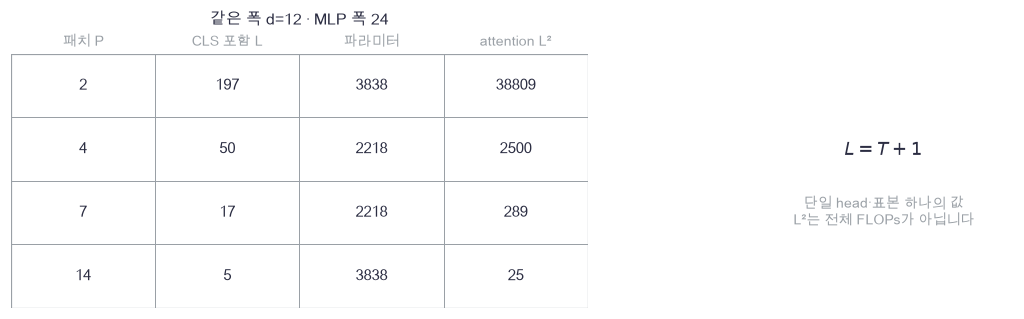

In [38]:
plot_patch_budget(patch_sizes, token_counts, budget_params, attention_entries)

🔍 **계산 크기 확인**

P=7에서는 패치 16개와 CLS를 합쳐 17토큰이므로 attention은 17×17=289개 값입니다. 패치 수가 네 배 가까이 늘면 attention 배열 원소는 약 열여섯 배로 늘지만, 학습 전체 시간이 그 비율과 정확히 같다는 뜻은 아닙니다. 파라미터 수는 패치 가중치와 위치 표가 반대 방향으로 변해 단순히 토큰 수만으로 정해지지 않습니다.

### ✏️ 연습 4 · 내용과 위치를 함께 옮기기

`position:(T+1,d)`과 CLS를 제외한 0부터 T−1까지의 `patch_order`를 받습니다. 준비된 `token_order`로 위치 표를 재정렬하는 한 줄을 채우세요.

In [39]:
def exercise_move_position(position,patch_order):
    """CLS 행은 남기고 내용과 같은 순서로 위치 행을 옮깁니다."""
    token_order=np.concatenate([np.array([0]),patch_order+1])
    raise NotImplementedError
    return moved

In [40]:
def check_move_position(candidate):
    """CLS 100을 유지하고 두 패치 위치 10·20만 바꿉니다."""
    actual=candidate(np.array([[100.],[10.],[20.]]),np.array([1,0]))
    np.testing.assert_array_equal(actual,[[100.],[20.],[10.]])  # 검산: 내용과 같은 순열을 위치 표에도 적용합니다.
run_check(check_move_position,exercise_move_position)

☐ exercise_move_position: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
moved = position[token_order].copy()
```

</details>

## 🔑 5. 실제 숫자를 분류하고 독립 자료에서 평가합니다

**이 절에서 가져갈 것:** 고정 예산으로 작은 ViT 전체를 학습하고, CLS·평균 읽기 두 실행의 손실·정확도와 한계를 기록합니다.

지금까지의 attention은 손으로 정했거나 초기화한 값입니다. 이제 MNIST 정답 숫자를 이용해 패치 임베딩부터 위치·CLS·attention·MLP·분류기까지 함께 학습합니다. 같은 초기 배열과 표본 순서에서 두 읽기 방법을 각각 학습합니다.

$$X:(N,28,28)\to B:(N,16,49)\to Z:(N,17,12)\to Y_f:(N,17,12)\to r:(N,12)\to\mathrm{logits}:(N,10).$$

패치는 7×7, 블록 하나, head 하나, MLP 폭 24입니다. 두 방식 모두 CLS 토큰이 attention에 참여하며 마지막 읽기만 다릅니다. 초기 CLS는 위치를 통해서도 수정되고, 학습 뒤에는 이미지별로 다른 정보를 모을 수 있습니다. 다음은 학습 전 고정 숫자 7의 실제 forward입니다.

> **용어** · **학습 파라미터**는 손실 미분으로 갱신하는 배열입니다. 위치·CLS도 여기에 포함됩니다. **정확도**는 최고 점수의 클래스가 정답인 표본 비율이며 CE와 다른 평가 숫자입니다.

In [41]:
# 쓰는 것: example_seven,example_patches (2절), init_vit,vit_forward (3절)
initial_params=init_vit(49,16,width=12,hidden=24,classes=10,seed=190)
initial_logits,initial_cache=vit_forward(example_patches,initial_params,'cls')
initial_encoded=initial_cache['encoded'][0]
initial_exp=np.exp(initial_logits-initial_logits.max(axis=1,keepdims=True))
initial_probabilities=initial_exp/initial_exp.sum(axis=1,keepdims=True)

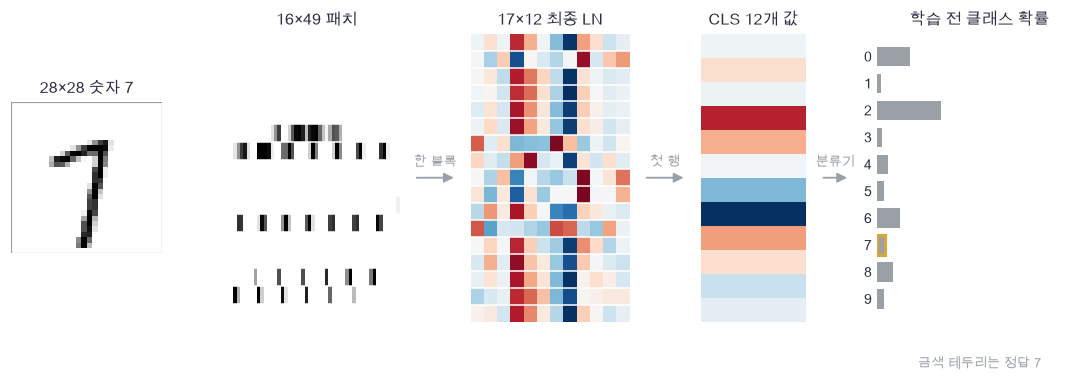

In [42]:
plot_classifier_flow(example_seven, example_patches[0], initial_encoded, initial_cache["pooled"][0], initial_probabilities[0])

🔍 **그림 확인과 고정 실험 계획**

17행에는 이미지 조각 16개와 CLS가 들어 있습니다. 최종 LN 뒤의 CLS 벡터가 10개 점수로 바뀌지만, 아직 학습하지 않아 7이 가장 높을 필요는 없습니다. 아래 실험은 test를 보기 전에 정한 설정으로 끝까지 실행하고 마지막 epoch 모델을 평가합니다.

| 항목 | 고정 설정 |
|---|---|
| train | MNIST train 파일의 앞 1,600장 |
| validation | 같은 파일의 다음 400장, 갱신에는 사용하지 않음 |
| test | 별도 MNIST test 파일의 앞 600장 |
| 초기화·순서 | 두 읽기 방법에 같은 초기 배열 seed 190, epoch 순서 seed 193 |
| 학습 | batch 64, 8 epoch, Adam 학습률 0.003, 총 200번 갱신 |
| 선택 | validation으로 epoch·seed를 다시 고르지 않고 마지막 모델 사용 |

화소를 255로 나누는 고정 변환 외에 전체 자료에서 통계를 맞추지 않습니다. LN은 각 토큰의 특징 안에서만 통계를 내므로 BN처럼 저장 통계의 train/eval 전환이 없습니다. dropout도 넣지 않았습니다.

> **용어** · **Adam**은 기울기의 이동 평균 $m_t=.9m_{t-1}+.1g_t$, 제곱 평균 $v_t=.999v_{t-1}+.001g_t^2$를 저장하고, $\hat m_t=m_t/(1-.9^t)$, $\hat v_t=v_t/(1-.999^t)$로 보정한 뒤 $\theta\leftarrow\theta-.003\hat m_t/(\sqrt{\hat v_t}+10^{-8})$로 갱신합니다.

> **용어** · **validation**은 학습 중 관찰하는 별도 자료, **test**는 고정 모델의 최종 평가 자료입니다. **epoch**는 학습 표본 전체를 한 번 방문하는 단위입니다.
>
> **코드** · `zip(a,b)`는 같은 위치의 항목을 묶습니다. `rng.permutation(N)`은 표본 번호를 섞어 한 epoch에 모두 한 번씩 방문하게 합니다. `np.argmax(...,axis=1)`은 각 표본에서 가장 높은 점수의 클래스 번호를 고릅니다.

In [43]:
def adam_update(params, gradients, first, second, step, learning_rate=.003):
    """각 파라미터의 두 이동 평균을 같은 갱신 번호로 편향 보정합니다."""
    for name in params:
        first[name] = .9*first[name]+.1*gradients[name]
        second[name] = .999*second[name]+.001*gradients[name]**2
        mhat = first[name]/(1-.9**step)
        vhat = second[name]/(1-.999**step)
        params[name] -= learning_rate*mhat/(np.sqrt(vhat)+1e-8)

In [44]:
# 쓰는 것: vit_forward,cross_entropy (3절)
def evaluate_vit(patches, labels, params, pooling='cls', use_position=True, batch_size=128):
    """고정 모델의 전체 표본 평균 CE·정확도를 계산합니다."""
    total_loss,correct = 0.,0
    for start in range(0,len(patches),batch_size):
        scores,_ = vit_forward(patches[start:start+batch_size],params,pooling,use_position)
        loss,_ = cross_entropy(scores,labels[start:start+batch_size])
        total_loss += len(scores)*loss
        correct += np.sum(scores.argmax(axis=1)==labels[start:start+batch_size])
    return total_loss/len(patches),correct/len(patches)

In [45]:
# 쓰는 것: vit_forward,vit_backward,cross_entropy (3절), adam_update,evaluate_vit (5절)
def train_vit(train_patches, train_labels, valid_patches, valid_labels, initial, pooling='cls', epochs=8, seed=193):
    """고정 설정으로 학습하고 마지막 epoch 모델과 학습·검증 기록을 반환합니다."""
    # 1. 초깃값과 optimizer 상태를 독립 복사합니다.
    params = {name:value.copy() for name,value in initial.items()}
    first = {name:np.zeros_like(value) for name,value in params.items()}
    second = {name:np.zeros_like(value) for name,value in params.items()}
    rng = np.random.default_rng(seed)
    history,step = [],0
    for epoch in range(1,epochs+1):
        order = rng.permutation(len(train_patches))
        total_loss = 0.
        # 2. 패치부터 분류 손실까지 미분한 뒤 모든 파라미터를 갱신합니다.
        for start in range(0,len(order),64):
            indices = order[start:start+64]
            logits,cache = vit_forward(train_patches[indices],params,pooling)
            loss,dlogits = cross_entropy(logits,train_labels[indices])
            _,gradients = vit_backward(dlogits,cache,params)
            step += 1
            adam_update(params,gradients,first,second,step)
            total_loss += len(indices)*loss
        # 3. epoch 끝의 고정 모델을 validation에서 평가합니다.
        valid_loss,valid_accuracy = evaluate_vit(valid_patches,valid_labels,params,pooling)
        history.append([epoch,total_loss/len(train_patches),valid_loss,valid_accuracy])
    return params,np.asarray(history)

In [46]:
# 쓰는 것: initial_params (5절), adam_update (5절)
parameter_count=sum(value.size for value in initial_params.values())
assert parameter_count==2218, "이 구조의 학습 파라미터 원소는 2,218개여야 합니다"
assert len(initial_params)==21, "위치·CLS·세 LN을 포함한 21개 배열을 학습합니다"
adam_probe={'w':np.array([1.,-2.])}
adam_first,adam_second={'w':np.zeros(2)},{'w':np.zeros(2)}
adam_update(adam_probe,{'w':np.array([2.,-4.])},adam_first,adam_second,1,learning_rate=.01)
np.testing.assert_allclose(adam_probe['w'],[.99,-1.99],atol=1e-9)  # 검산: 첫 Adam 보정 후 기울기 부호 반대로 약 .01 이동합니다.
print('두 모델의 공통 학습 파라미터:',parameter_count,'· Adam 첫 갱신 통과')

두 모델의 공통 학습 파라미터: 2218 · Adam 첫 갱신 통과


In [47]:
# 쓰는 것: load_mnist (준비), patchify (1절)
mnist_raw_train,mnist_train_labels,mnist_raw_test,mnist_test_labels=load_mnist(download=True,normalize=False)
mnist_train_images=mnist_raw_train[:1600].reshape(-1,28,28)/255.
mnist_valid_images=mnist_raw_train[1600:2000].reshape(-1,28,28)/255.
mnist_test_images=mnist_raw_test[:600].reshape(-1,28,28)/255.
mnist_train_y=mnist_train_labels[:1600].copy()
mnist_valid_y=mnist_train_labels[1600:2000].copy()
mnist_test_y=mnist_test_labels[:600].copy()
mnist_train_patches=patchify(mnist_train_images,7)
mnist_valid_patches=patchify(mnist_valid_images,7)
mnist_test_patches=patchify(mnist_test_images,7)
del mnist_raw_train,mnist_raw_test
print('train/validation/test:',len(mnist_train_y),len(mnist_valid_y),len(mnist_test_y))
print('각 방식의 학습 예산: 8epoch × 25batch = 200updates')

train/validation/test: 1600 400 600
각 방식의 학습 예산: 8epoch × 25batch = 200updates


In [48]:
# 쓰는 것: initial_params,train_vit,evaluate_vit (5절), mnist_train_patches,mnist_train_y,mnist_valid_patches,mnist_valid_y (자료 셀)
training_started=perf_counter()
pooling_names=['cls','mean']
trained_models={}
training_histories=[]
initial_validation=[]
for pooling in pooling_names:
    initial_validation.append(evaluate_vit(mnist_valid_patches,mnist_valid_y,initial_params,pooling))
    model,history=train_vit(mnist_train_patches,mnist_train_y,mnist_valid_patches,mnist_valid_y,initial_params,pooling,epochs=8,seed=193)
    trained_models[pooling]=model
    training_histories.append(history)
    print(pooling,'학습 전 validation CE/정확도:',initial_validation[-1])
    print(pooling,'마지막 validation CE/정확도:',history[-1,2:])
training_histories=np.asarray(training_histories)
print('두 모델 학습 시간:',round(perf_counter()-training_started,2),'초')

cls 학습 전 validation CE/정확도: (2.759102133785685, np.float64(0.075))
cls 마지막 validation CE/정확도: [1.18600937 0.59      ]


mean 학습 전 validation CE/정확도: (2.4775928709027566, np.float64(0.06))
mean 마지막 validation CE/정확도: [0.97779651 0.6425    ]
두 모델 학습 시간: 0.73 초


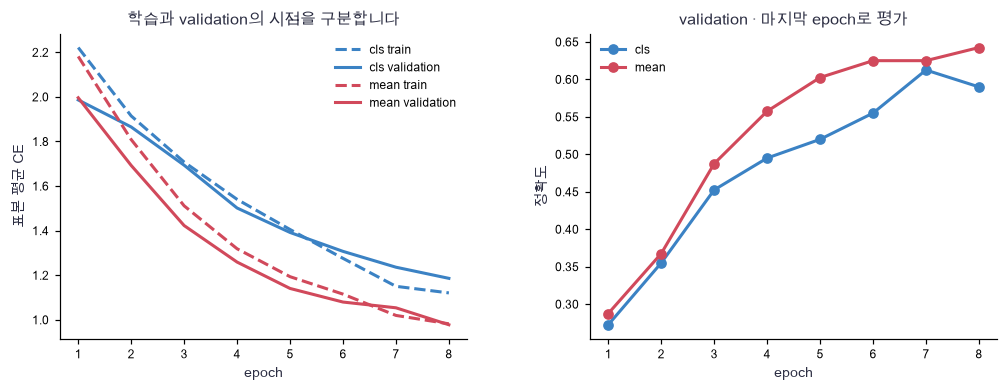

In [49]:
plot_vit_training(training_histories, pooling_names)

🔍 **학습 곡선 확인**

train CE는 각 배치의 **갱신 직전** 손실을 표본 수로 가중평균합니다. validation CE·정확도는 epoch 끝의 고정 모델로 계산합니다. 두 CE의 차이를 같은 시점의 일반화 격차로 해석하지 않습니다. 각 읽기는 한 초기화·한 순서의 실행이므로 곡선에 seed 간 오차 막대는 붙이지 않습니다.

손실과 정확도가 어떻게 변했는지 실제 숫자를 읽습니다. 더 좋은 마지막 값이 보였다고 그 읽기가 모든 모델·초기화에서 우수하다고 결론내리지 않습니다. 다음은 모든 test 600장을 사용한 최종 평가입니다.

In [50]:
# 쓰는 것: trained_models,pooling_names,evaluate_vit,vit_forward,parameter_count,training_histories (5절), mnist_test_patches,mnist_test_y (자료 셀)
test_predictions=[]
for pooling in pooling_names:
    model=trained_models[pooling]
    test_loss,test_accuracy=evaluate_vit(mnist_test_patches,mnist_test_y,model,pooling)
    print(pooling,'test CE=',round(test_loss,4),'정확도=',round(test_accuracy,4))
    scores,_=vit_forward(mnist_test_patches[:10],model,pooling)
    test_predictions.append(scores.argmax(axis=1))
    assert sum(value.size for value in model.values())==parameter_count, "두 방식의 파라미터 수는 그대로 같아야 합니다"
    assert np.isfinite(test_loss), "최종 test 손실이 유한해야 합니다"
assert np.all(np.isfinite(training_histories)), "학습·검증 기록이 모두 유한해야 합니다"
test_predictions=np.asarray(test_predictions)
print('같은 test 600장·마지막 모델·모든 실행 기록 확인')

cls test CE= 1.245 정확도= 0.5517
mean test CE= 1.1291 정확도= 0.6
같은 test 600장·마지막 모델·모든 실행 기록 확인


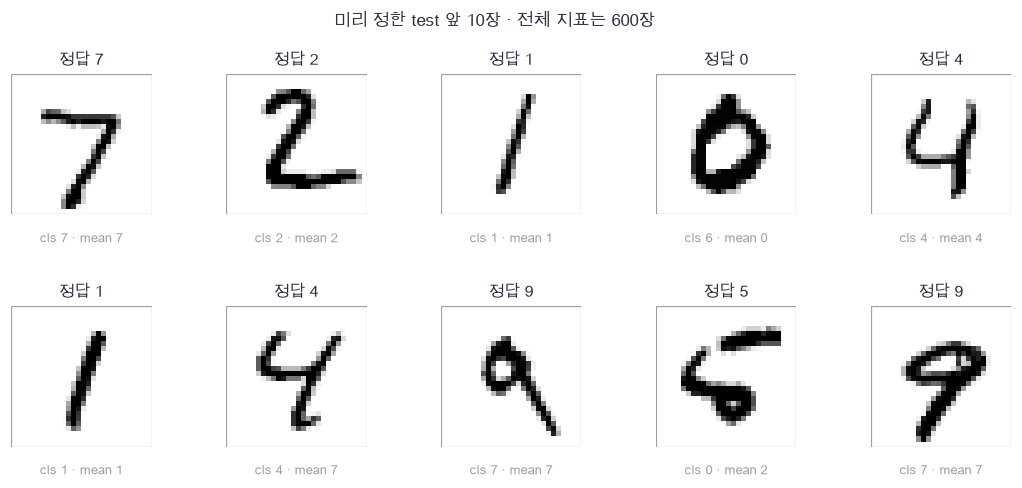

In [51]:
plot_vit_predictions(mnist_test_images[:10], mnist_test_y[:10], test_predictions, pooling_names)

🔍 **어떤 표본을 보여 주는가**

그림은 test 앞 10장입니다. 잘 맞힌 예를 골라 모으지 않았으며 전체 지표는 600장 모두에서 냈습니다. 고정 데이터·단일 초기화·작은 모델의 결과이고, 원 ViT의 대규모 사전학습 성능과 직접 비교하지 않습니다.

마지막으로 미리 정한 **CLS 읽기 모델**이 고정 숫자 7에서 어떤 패치를 읽는지 봅니다. 이 7은 개념 설명용 train 예시이며 독립 test 결과로 세지 않습니다. attention 행 전체에는 CLS 자신도 있어 패치 16개의 확률 합은 보통 1보다 작습니다. 아래에서 따로 재정규화하지 않고 원래 확률을 표시합니다.

In [52]:
# 쓰는 것: example_patches,example_seven (2절), trained_models,vit_forward (5절)
attention_logits,attention_model_cache=vit_forward(example_patches,trained_models['cls'],'cls')
_,q_display,k_display,v_display,learned_attention,context_display=attention_model_cache['attention']
cls_self_probability=float(learned_attention[0,0,0])
cls_patch_map=learned_attention[0,0,1:].reshape(4,4)
attention_prediction=int(attention_logits.argmax(axis=1)[0])
np.testing.assert_allclose(cls_self_probability+cls_patch_map.sum(),1.)  # 검산: CLS 자신과 모든 패치 확률을 합하면 1입니다.
print('CLS가 자신에게 준 확률:',round(cls_self_probability,4),'· 패치 확률 합:',round(cls_patch_map.sum(),4))

CLS가 자신에게 준 확률: 0.007 · 패치 확률 합: 0.993


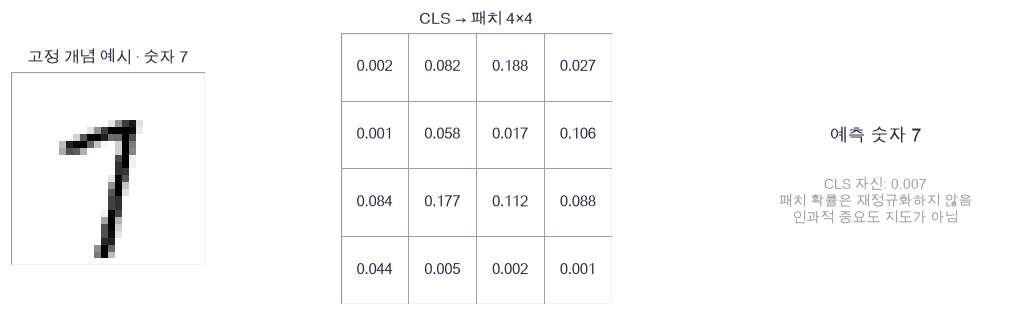

In [53]:
plot_cls_attention(example_seven, cls_patch_map, cls_self_probability, attention_prediction)

🔍 **attention 그림의 범위**

이 지도는 한 head의 CLS query가 각 value를 읽는 가중치입니다. 값이 크다고 그 화소가 예측에 인과적으로 가장 중요하다는 뜻은 아닙니다. value·출력 투영·MLP·잔차 경로도 예측에 관여합니다. 패치를 가리는 별도 개입 실험을 하지 않았으므로 가중합의 구조를 확인한 것으로 해석합니다.

모델 폭·패치 크기·학습 횟수를 바꾸려면 먼저 validation에서 비교하고, test를 반복해 보고 설정을 고르지 않습니다. 패치 크기가 바뀌면 패치 임베딩과 위치 표의 shape가 함께 바뀌므로 새 모델 초기화가 필요합니다.

### ✏️ 연습 5 · 전체 표본 분모의 손실 평균

서로 크기가 다른 배치의 평균 손실 `batch_losses`와 표본 수 `counts`가 주어집니다. 전체 평균 손실 한 줄을 채우세요.

In [54]:
def exercise_weighted_loss(batch_losses,counts):
    """작은 마지막 배치까지 같은 표본 분모로 합칩니다."""
    raise NotImplementedError
    return total

In [55]:
def check_weighted_loss(candidate):
    """두 표본의 손실 1과 한 표본의 손실 4를 함께 평균합니다."""
    actual=candidate(np.array([1.,4.]),np.array([2,1]))
    np.testing.assert_allclose(actual,2.)  # 검산: (2×1+1×4)/3=2입니다.
run_check(check_weighted_loss,exercise_weighted_loss)

☐ exercise_weighted_loss: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.sum(batch_losses*counts)/np.sum(counts)
```

</details>

## ✏️ 전체 연결 연습 A–D

긴 학습 없이 작은 배열로 패치 축·공유 파라미터·순열·계산 크기를 다시 확인합니다.

### ✏️ 연습 A · 위치 파라미터의 공유 축

`dz:(N,L,d)`는 위치 벡터를 더한 토큰의 기울기입니다. `position:(L,d)`의 기울기 한 줄을 채우세요.

In [56]:
def exercise_position_gradient(dz):
    """모든 표본에 공유된 위치 벡터의 기여를 합합니다."""
    raise NotImplementedError
    return dposition

In [57]:
def check_position_gradient(candidate):
    """표본 둘에서 온 각 위치의 기여를 따로 더합니다."""
    actual=candidate(np.array([[[1.,2.],[3.,4.]],[[5.,6.],[7.,8.]]]))
    np.testing.assert_array_equal(actual,[[6.,8.],[10.,12.]])  # 검산: 표본 축만 더해 L,d를 남깁니다.
run_check(check_position_gradient,exercise_position_gradient)

☐ exercise_position_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dposition = dz.sum(axis=0)
```

</details>

### ✏️ 연습 B · mean 읽기의 입력 기울기

CLS 포함 `tokens`와 모아 읽은 벡터의 기울기 `dpooled:(N,d)`를 받습니다. 준비된 영 배열의 패치 행에 기울기를 나누는 한 줄을 채우세요.

In [58]:
def exercise_mean_backward(tokens,dpooled):
    """직접 읽기 경로에서는 CLS 행에 0, 패치 행에 같은 1/T 기여를 줍니다."""
    dtokens=np.zeros_like(tokens)
    patch_count=tokens.shape[1]-1
    raise NotImplementedError
    return dtokens

In [59]:
def check_mean_backward(candidate):
    """패치 둘이 평균될 때 상류 기울기 4·6을 반씩 나눕니다."""
    actual=candidate(np.zeros((1,3,2)),np.array([[4.,6.]]))
    np.testing.assert_array_equal(actual,[[[0.,0.],[2.,3.],[2.,3.]]])  # 검산: 직접 CLS 기여는 0이고 패치는 절반씩입니다.
run_check(check_mean_backward,exercise_mean_backward)

☐ exercise_mean_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dtokens[:,1:,:] = dpooled[:,None,:]/patch_count
```

</details>

### ✏️ 연습 C · 한 head의 attention 배열 크기

회색 28×28 이미지와 패치 크기 `patch_size`에서 CLS를 포함한 길이 `length`와 표본당 attention 원소 수 `entries`를 두 줄로 채우세요.

In [60]:
def exercise_attention_size(patch_size):
    """전체 FLOPs와 구분해 L×L 확률 배열 원소만 셉니다."""
    raise NotImplementedError
    return length,entries

In [61]:
def check_attention_size(candidate):
    """패치7이면 16개 조각과 CLS 하나입니다."""
    assert candidate(7)==(17,289), "CLS를 포함하면 17토큰, attention은289개여야 합니다"
run_check(check_attention_size,exercise_attention_size)

☐ exercise_attention_size: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
length = (28//patch_size)**2+1
entries = length**2
```

</details>

### ✏️ 연습 D · 토큰별 LN의 affine 기울기

`dy,normalized:(N,L,d)`가 주어집니다. 특징마다 공유되는 `dgamma`, `dbeta` 두 줄을 채우세요.

In [62]:
def exercise_ln_affine(dy,normalized):
    """표본·토큰 축을 합하고 특징 축을 남깁니다."""
    raise NotImplementedError
    return dgamma,dbeta

In [63]:
def check_ln_affine(candidate):
    """표본 하나·토큰 둘의 특징별 기여를 손으로 더합니다."""
    dg,db=candidate(np.array([[[1.,2.],[3.,4.]]]),np.array([[[-1.,1.],[1.,-1.]]]))
    np.testing.assert_allclose(dg,[2.,-2.])  # 검산: -1+3=2, 2-4=-2입니다.
    np.testing.assert_allclose(db,[4.,6.])  # 검산: 토큰 두 개에서 1+3,2+4를 더합니다.
run_check(check_ln_affine,exercise_ln_affine)

☐ exercise_ln_affine: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dgamma = np.sum(dy*normalized,axis=(0,1))
dbeta = np.sum(dy,axis=(0,1))
```

</details>

## ✏️ 다음 단계 준비도

**설명 확인:** 패치 재배열과 선형 임베딩은 어떻게 다른가요? encoder를 지나기 전 CLS만 읽으면 이미지 내용을 알 수 없는 이유는 무엇인가요? 이 노트북의 mean 읽기와 CLS 자체를 없앤 구조의 차이를 말할 수 있나요?

**수식 확인:** attention softmax의 평균 항과 Q·K·V 세 입력 미분을 유도할 수 있나요? 위치·CLS·LN γ·β가 공유하는 축에 맞춰 기울기를 합할 수 있나요? 두 잔차 경로의 직접 항을 빠뜨리지 않았나요?

**구현 확인:** `(N,H,W)`에서 `(N,T,P²)`로 바꾸는 transpose의 축을 적고 역변환할 수 있나요? LN은 토큰 축과 특징 축 중 어느 쪽에서 통계를 구하나요? 21개 파라미터 배열 모두 optimizer와 수치미분 대상에 들어가는지 확인할 수 있나요?

**변형 검산:** 위치 없이 패치만 섞을 때 encoded 토큰과 분류 점수는 각각 어떻게 변하나요? 위치 슬롯을 고정한 순열과 위치를 함께 옮긴 순열은 어떻게 다른가요? 패치7을14로 바꾸면 임베딩·위치·attention의 shape와 파라미터 수를 다시 계산할 수 있나요?

[20](20_sequence_encoder_decoder.ipynb)의 cross-attention에서는 query와 key/value의 출처가 달라집니다. [21](21_sets_graph_attention.ipynb)에서는 순열 대칭을 유지할지 위치·이웃 구조로 제한할지가 모델 설계의 출발점이 됩니다.